# ARIMA Product Forecasting — Model Development

This notebook builds and validates an ARIMA model for forecasting product demand.

## Objectives
1. Load cleaned time series data
2. Test for stationarity (ADF test)
3. Apply differencing if needed
4. Determine optimal ARIMA parameters (p, d, q)
5. Split data into train-test sets
6. Fit ARIMA model and evaluate performance
7. Perform residual diagnostics
8. Generate 36-60 month forecast
9. Visualize and export results

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from pmdarima import auto_arima
from sklearn.metrics import mean_squared_error, mean_absolute_error
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

# Set plot style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
%matplotlib inline

## 1. Load Cleaned Data

Time Series Shape: (62, 1)

First 5 records:
            Total_Number
Date                    
2024-11-01          3888
2024-12-01          2988
2025-01-01          4008
2025-02-01          4368
2025-03-01          4332

Last 5 records:
            Total_Number
Date                    
2029-08-01          3528
2029-09-01          3528
2029-10-01          3480
2029-11-01          3516
2029-12-01          3468


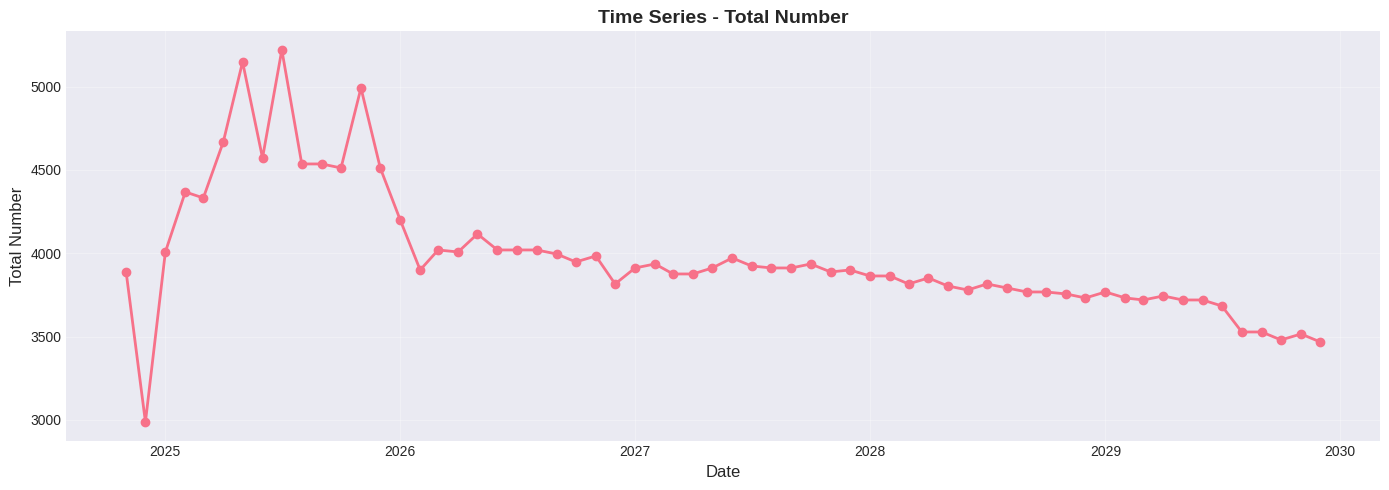

In [2]:
# Load the cleaned time series from EDA notebook
df_ts = pd.read_csv('../outputs/cleaned_timeseries.csv', index_col='Date', parse_dates=True)

print("Time Series Shape:", df_ts.shape)
print("\nFirst 5 records:")
print(df_ts.head())
print("\nLast 5 records:")
print(df_ts.tail())

# Plot the data
plt.figure(figsize=(14, 5))
plt.plot(df_ts.index, df_ts['Total_Number'], marker='o', linestyle='-', linewidth=2)
plt.title('Time Series - Total Number', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Number', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Stationarity Test (ADF)

In [3]:
def adf_test(timeseries, title=''):
    """
    Perform Augmented Dickey-Fuller test for stationarity
    """
    print(f"Augmented Dickey-Fuller Test: {title}")
    print("="*60)
    
    result = adfuller(timeseries.dropna(), autolag='AIC')
    
    print(f'ADF Statistic: {result[0]:.6f}')
    print(f'p-value: {result[1]:.6f}')
    print(f'Number of Lags Used: {result[2]}')
    print(f'Number of Observations: {result[3]}')
    print('\nCritical Values:')
    for key, value in result[4].items():
        print(f'   {key}: {value:.3f}')
    
    if result[1] <= 0.05:
        print("\n✓ Series is STATIONARY (reject null hypothesis, p-value <= 0.05)")
        return True
    else:
        print("\n✗ Series is NON-STATIONARY (fail to reject null hypothesis, p-value > 0.05)")
        return False

# Test original series
is_stationary = adf_test(df_ts['Total_Number'], title='Original Series')
print("\n" + "="*60)

Augmented Dickey-Fuller Test: Original Series
ADF Statistic: -3.779554
p-value: 0.003124
Number of Lags Used: 8
Number of Observations: 53

Critical Values:
   1%: -3.560
   5%: -2.918
   10%: -2.597

✓ Series is STATIONARY (reject null hypothesis, p-value <= 0.05)



## 3. Differencing (if needed)

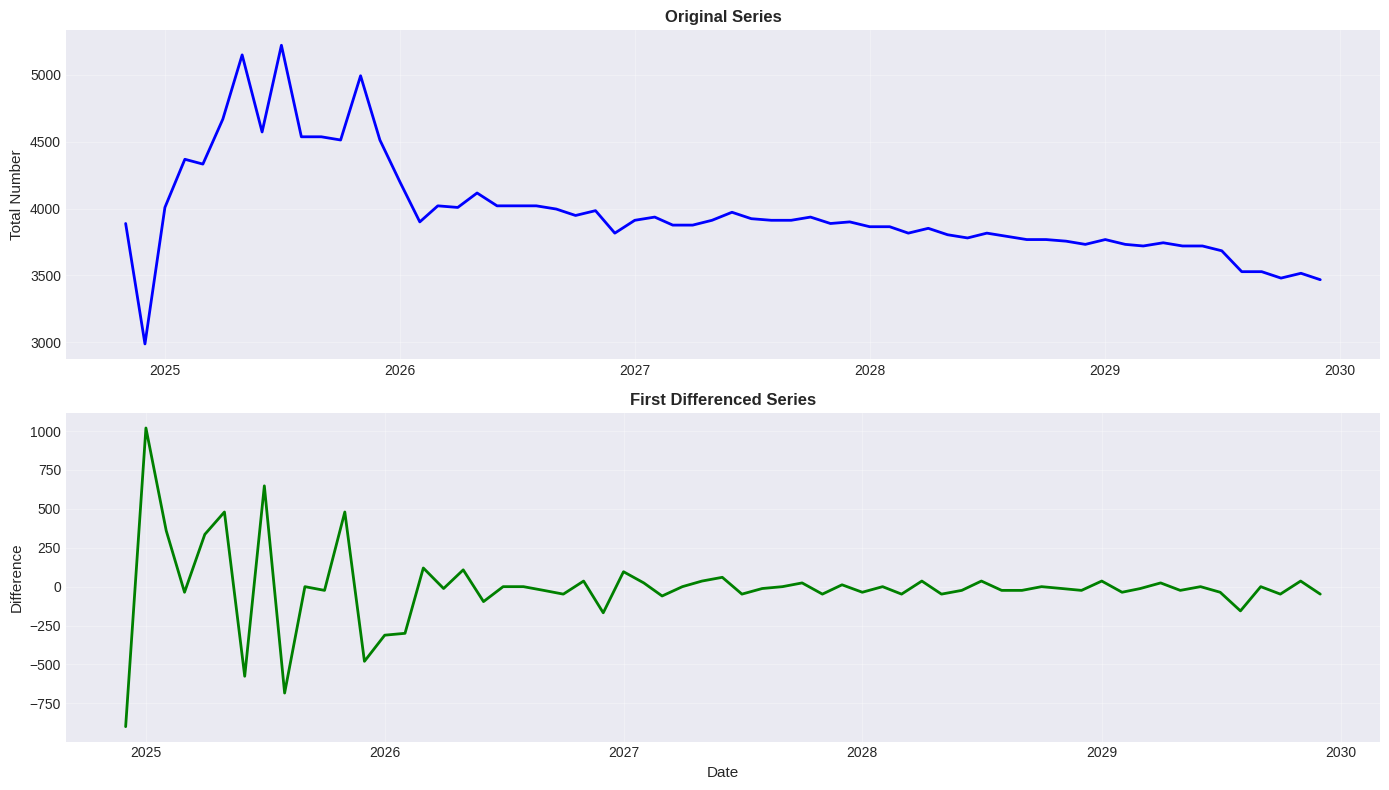



Augmented Dickey-Fuller Test: First Differenced Series
ADF Statistic: -5.155461
p-value: 0.000011
Number of Lags Used: 11
Number of Observations: 49

Critical Values:
   1%: -3.571
   5%: -2.923
   10%: -2.599

✓ Series is STATIONARY (reject null hypothesis, p-value <= 0.05)


In [4]:
# Apply first-order differencing
df_ts['First_Diff'] = df_ts['Total_Number'].diff()

# Plot original vs differenced
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Original
axes[0].plot(df_ts.index, df_ts['Total_Number'], linewidth=2, color='blue')
axes[0].set_title('Original Series', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Total Number', fontsize=11)
axes[0].grid(True, alpha=0.3)

# First Difference
axes[1].plot(df_ts.index, df_ts['First_Diff'], linewidth=2, color='green')
axes[1].set_title('First Differenced Series', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Difference', fontsize=11)
axes[1].set_xlabel('Date', fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../outputs/visualizations/03_stationarity_tests.png', dpi=300, bbox_inches='tight')
plt.show()

# Test differenced series
print("\n")
is_diff_stationary = adf_test(df_ts['First_Diff'], title='First Differenced Series')

## 4. ACF and PACF Plots

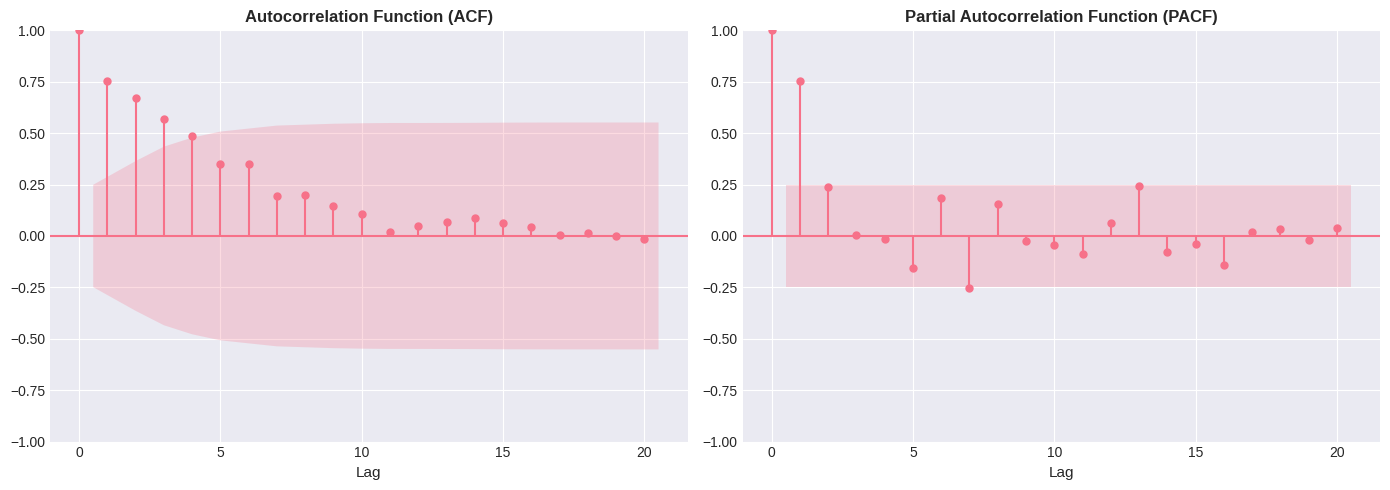

In [5]:
# Determine which series to use for ACF/PACF (differenced if original is non-stationary)
series_for_analysis = df_ts['First_Diff'].dropna() if not is_stationary else df_ts['Total_Number']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ACF
plot_acf(series_for_analysis, lags=20, ax=axes[0])
axes[0].set_title('Autocorrelation Function (ACF)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Lag', fontsize=11)

# PACF
plot_pacf(series_for_analysis, lags=20, ax=axes[1])
axes[1].set_title('Partial Autocorrelation Function (PACF)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Lag', fontsize=11)

plt.tight_layout()
plt.savefig('../outputs/visualizations/04_acf_pacf.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Train-Test Split

Total Data Points: 62
Training Set: 49 points (2024-11-01 00:00:00 to 2028-11-01 00:00:00)
Test Set: 13 points (2028-12-01 00:00:00 to 2029-12-01 00:00:00)


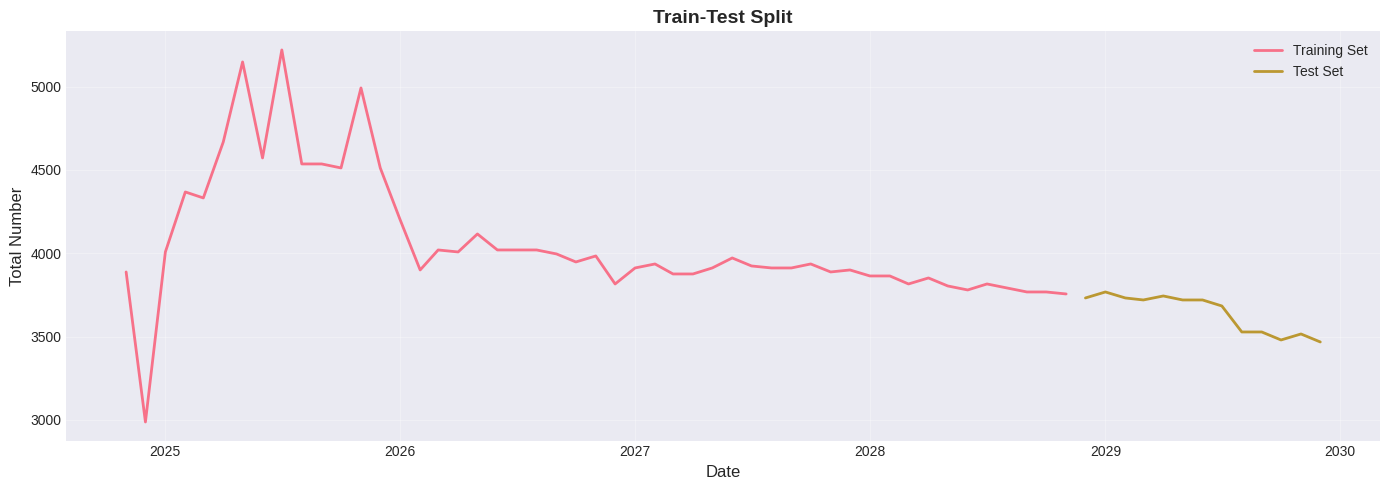

In [6]:
# Split data: use 80% for training, 20% for testing
train_size = int(len(df_ts) * 0.8)
train = df_ts['Total_Number'][:train_size]
test = df_ts['Total_Number'][train_size:]

print(f"Total Data Points: {len(df_ts)}")
print(f"Training Set: {len(train)} points ({train.index.min()} to {train.index.max()})")
print(f"Test Set: {len(test)} points ({test.index.min()} to {test.index.max()})")

# Visualize split
plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label='Training Set', linewidth=2)
plt.plot(test.index, test, label='Test Set', linewidth=2)
plt.title('Train-Test Split', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Number', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Auto ARIMA - Find Optimal Parameters

In [7]:
# Use auto_arima to find best parameters
print("Running Auto ARIMA to find optimal parameters...")
print("This may take a few minutes...\n")

auto_model = auto_arima(
    train,
    start_p=0, start_q=0,
    max_p=5, max_q=5,
    d=None,  # Let auto_arima determine d
    seasonal=False,  # Set to True if seasonal pattern exists
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore',
    trace=True
)

print("\n" + "="*60)
print("BEST MODEL FOUND")
print("="*60)
print(auto_model.summary())

Running Auto ARIMA to find optimal parameters...
This may take a few minutes...

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=687.496, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=678.281, Time=0.06 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=680.865, Time=0.05 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=685.500, Time=0.02 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=680.218, Time=0.08 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=680.615, Time=0.18 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.20 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=676.308, Time=0.04 sec
 ARIMA(2,1,0)(0,0,0)[0]             : AIC=678.228, Time=0.08 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=678.615, Time=0.11 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=678.872, Time=0.05 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=679.681, Time=0.16 sec

Best model:  ARIMA(1,1,0)(0,0,0)[0]          
Total fit time: 1.052 seconds

BEST MODEL FOUND
     

## 7. Fit ARIMA Model and Make Predictions

In [8]:
# Extract optimal parameters
best_order = auto_model.order
print(f"Optimal ARIMA Order: {best_order}")

# Fit ARIMA model on training data
model = ARIMA(train, order=best_order)
fitted_model = model.fit()

print("\nModel Summary:")
print(fitted_model.summary())

Optimal ARIMA Order: (1, 1, 0)

Model Summary:
                               SARIMAX Results                                
Dep. Variable:           Total_Number   No. Observations:                   49
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -336.154
Date:                Sun, 07 Dec 2025   AIC                            676.308
Time:                        15:08:31   BIC                            680.050
Sample:                    11-01-2024   HQIC                           677.722
                         - 11-01-2028                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4868      0.059     -8.205      0.000      -0.603      -0.370
sigma2       7.39e+04   1.04e+04      7.120      0.000    5.36e+04    9.42e+04
Ljung

In [9]:
# Make predictions on test set
predictions = fitted_model.forecast(steps=len(test))

# Calculate error metrics
mse = mean_squared_error(test, predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(test, predictions)
mape = np.mean(np.abs((test - predictions) / test)) * 100

print("\n" + "="*60)
print("MODEL PERFORMANCE ON TEST SET")
print("="*60)
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print("="*60)


MODEL PERFORMANCE ON TEST SET
Mean Squared Error (MSE): 26402.18
Root Mean Squared Error (RMSE): 162.49
Mean Absolute Error (MAE): 119.87
Mean Absolute Percentage Error (MAPE): 3.39%


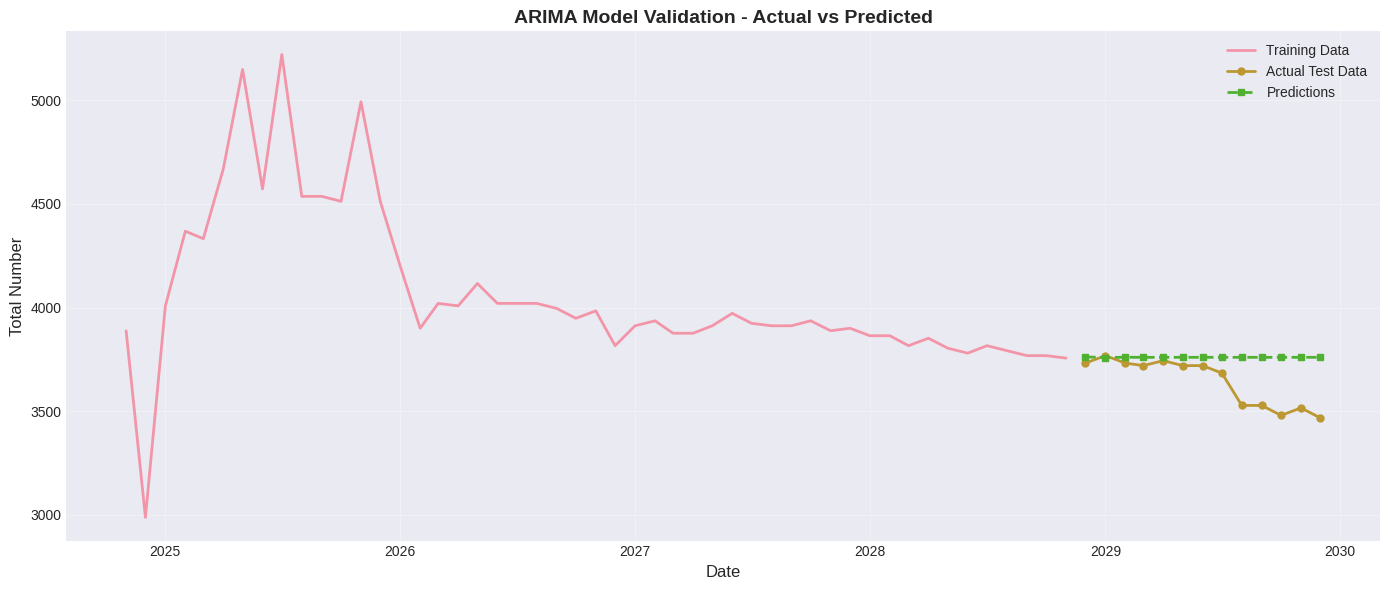

In [10]:
# Plot actual vs predicted on test set
plt.figure(figsize=(14, 6))
plt.plot(train.index, train, label='Training Data', linewidth=2, alpha=0.7)
plt.plot(test.index, test, label='Actual Test Data', linewidth=2, marker='o', markersize=5)
plt.plot(test.index, predictions, label='Predictions', linewidth=2, marker='s', markersize=5, linestyle='--')
plt.title('ARIMA Model Validation - Actual vs Predicted', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Number', fontsize=12)
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/visualizations/07_train_test_validation.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Residual Diagnostics

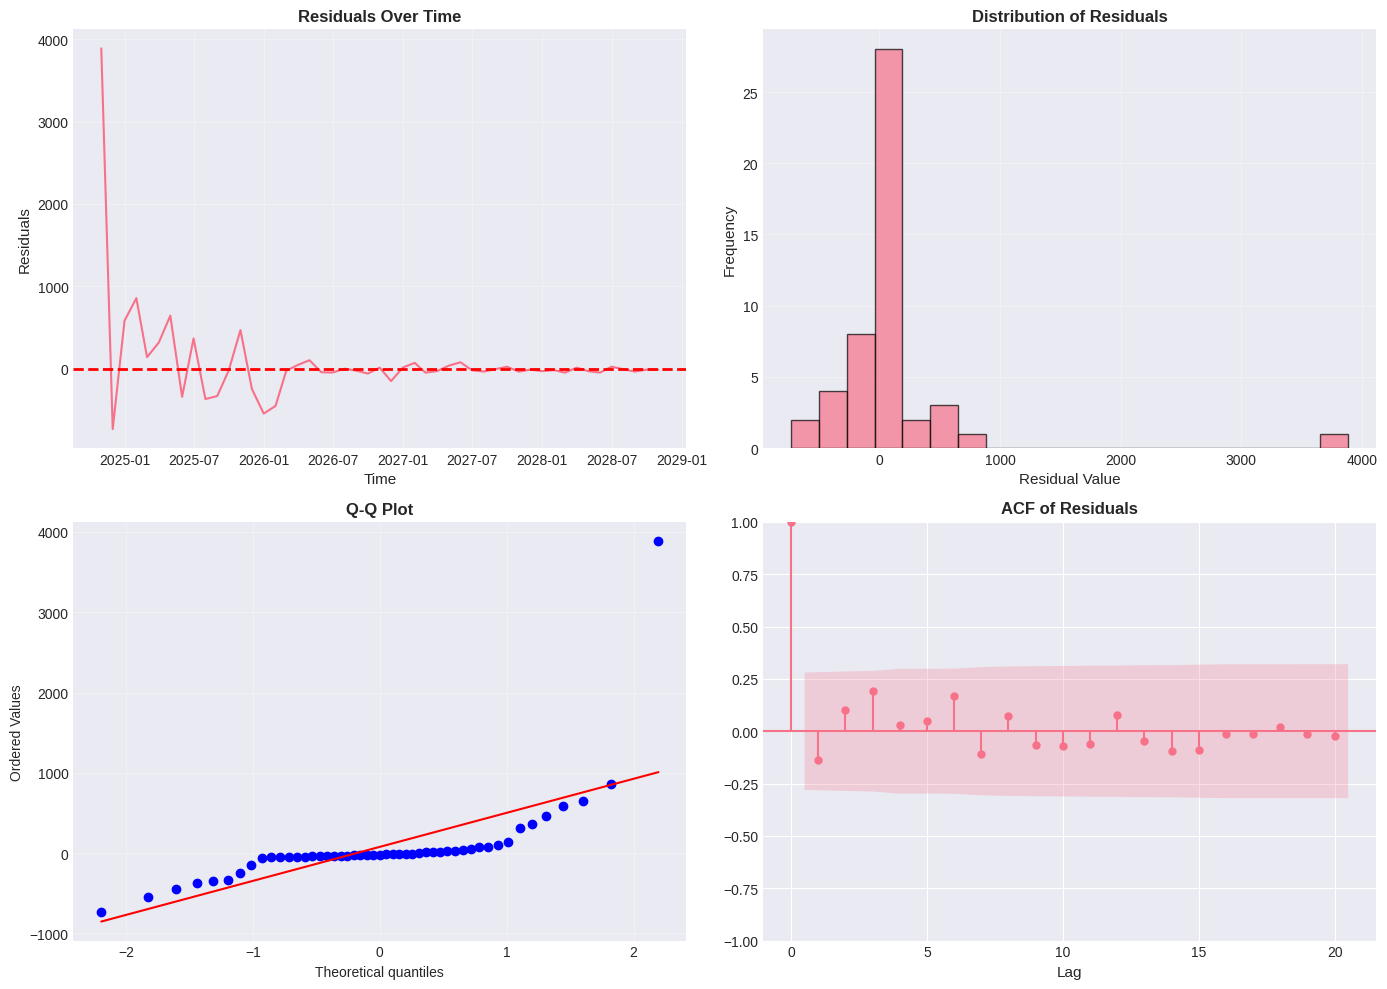

In [11]:
# Get residuals
residuals = fitted_model.resid

# Create diagnostic plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Residuals over time
axes[0, 0].plot(residuals, linewidth=1.5)
axes[0, 0].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[0, 0].set_title('Residuals Over Time', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Time', fontsize=11)
axes[0, 0].set_ylabel('Residuals', fontsize=11)
axes[0, 0].grid(True, alpha=0.3)

# 2. Histogram of residuals
axes[0, 1].hist(residuals, bins=20, edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Distribution of Residuals', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Residual Value', fontsize=11)
axes[0, 1].set_ylabel('Frequency', fontsize=11)
axes[0, 1].grid(True, alpha=0.3)

# 3. Q-Q plot
stats.probplot(residuals, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# 4. ACF of residuals
plot_acf(residuals, lags=20, ax=axes[1, 1])
axes[1, 1].set_title('ACF of Residuals', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Lag', fontsize=11)

plt.tight_layout()
plt.savefig('../outputs/visualizations/05_residual_diagnostics.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# Ljung-Box test for autocorrelation in residuals
lb_test = acorr_ljungbox(residuals, lags=10, return_df=True)
print("\nLjung-Box Test (tests for autocorrelation in residuals):")
print("="*60)
print(lb_test)
print("\nIf p-values > 0.05, residuals are white noise (good!)")


Ljung-Box Test (tests for autocorrelation in residuals):
     lb_stat  lb_pvalue
1   0.970733   0.324497
2   1.501032   0.472123
3   3.521305   0.318009
4   3.572134   0.466995
5   3.704055   0.592761
6   5.354725   0.499186
7   6.080163   0.530421
8   6.381704   0.604557
9   6.638209   0.674729
10  6.957559   0.729445

If p-values > 0.05, residuals are white noise (good!)


## 9. Retrain on Full Dataset

In [13]:
# Retrain model on full dataset for final forecasting
print("Retraining model on full dataset...")
final_model = ARIMA(df_ts['Total_Number'], order=best_order)
final_fitted = final_model.fit()

print("\n✓ Model retrained successfully")
print(f"AIC: {final_fitted.aic:.2f}")
print(f"BIC: {final_fitted.bic:.2f}")

Retraining model on full dataset...

✓ Model retrained successfully
AIC: 845.08
BIC: 849.30


## 10. Generate 36-60 Month Forecast

In [14]:
# Forecast next 60 months (5 years)
forecast_steps = 60
forecast_result = final_fitted.get_forecast(steps=forecast_steps)

# Get forecast values and confidence intervals
forecast_values = forecast_result.predicted_mean
forecast_ci = forecast_result.conf_int(alpha=0.05)  # 95% confidence interval

# Create forecast dataframe
forecast_dates = pd.date_range(start=df_ts.index[-1] + pd.DateOffset(months=1), periods=forecast_steps, freq='MS')
forecast_df = pd.DataFrame({
    'Date': forecast_dates,
    'Forecast': forecast_values.values,
    'Lower_CI': forecast_ci.iloc[:, 0].values,
    'Upper_CI': forecast_ci.iloc[:, 1].values
})
forecast_df.set_index('Date', inplace=True)

print(f"\nGenerated {forecast_steps}-month forecast")
print(f"Forecast Period: {forecast_df.index.min().strftime('%Y-%m')} to {forecast_df.index.max().strftime('%Y-%m')}")
print("\nFirst 10 forecast values:")
print(forecast_df.head(10))
print("\nLast 10 forecast values:")
print(forecast_df.tail(10))


Generated 60-month forecast
Forecast Period: 2030-01 to 2034-12

First 10 forecast values:
               Forecast     Lower_CI     Upper_CI
Date                                             
2030-01-01  3490.995676  3014.813617  3967.177736
2030-02-01  3479.978986  2943.061554  4016.896419
2030-03-01  3485.256825  2840.294976  4130.218674
2030-04-01  3482.728336  2769.291227  4196.165445
2030-05-01  3483.939676  2697.848812  4270.030539
2030-06-01  3483.359351  2635.363683  4331.355019
2030-07-01  3483.637371  2575.920607  4391.354135
2030-08-01  3483.504178  2520.683214  4446.325142
2030-09-01  3483.567988  2468.211462  4498.924513
2030-10-01  3483.537418  2418.424371  4548.650465

Last 10 forecast values:
              Forecast     Lower_CI     Upper_CI
Date                                            
2034-03-01  3483.54732  1163.177998  5803.916641
2034-04-01  3483.54732  1140.949894  5826.144745
2034-05-01  3483.54732  1118.930732  5848.163907
2034-06-01  3483.54732  1097.114728  

## 11. Visualize Final Forecast

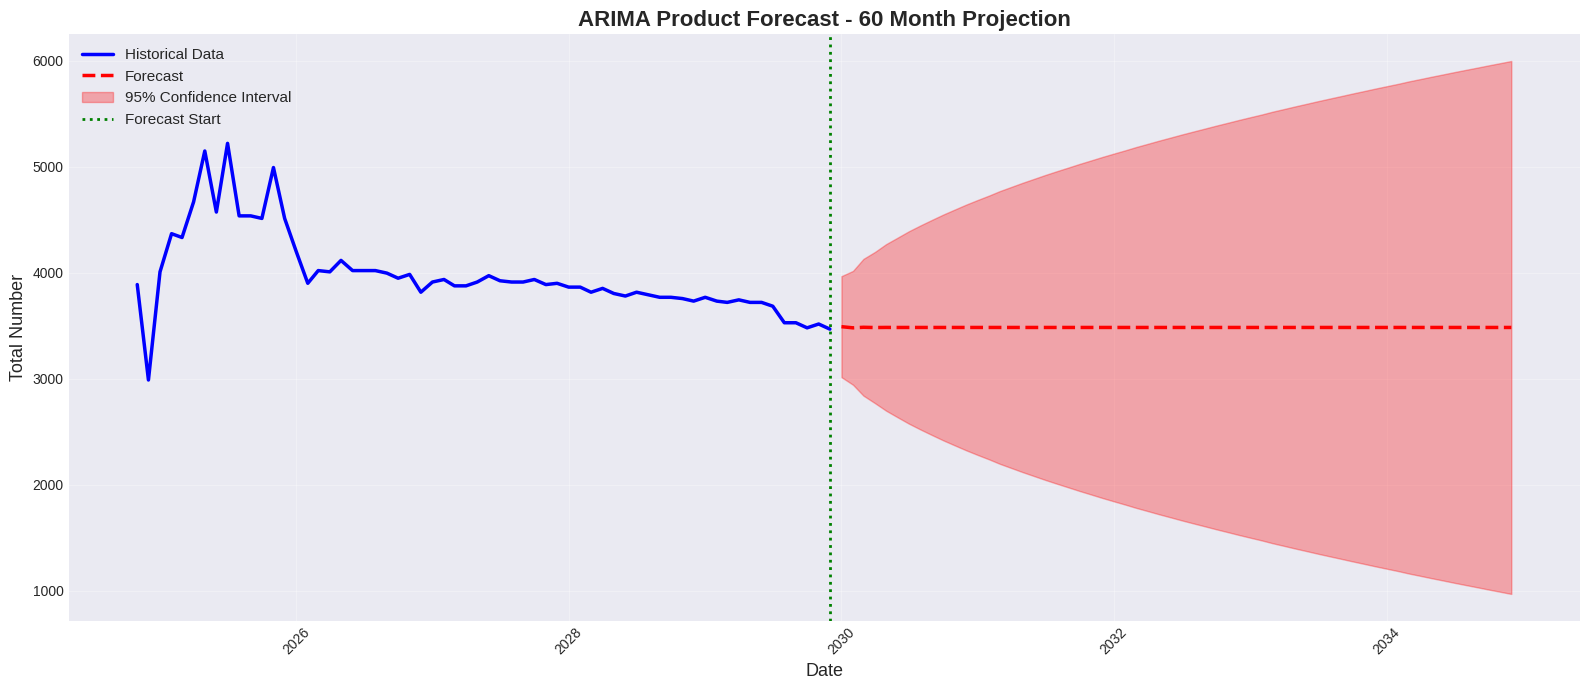

Forecast visualization saved to: outputs/visualizations/06_forecast_plot.png


In [15]:
# Create comprehensive forecast visualization
plt.figure(figsize=(16, 7))

# Plot historical data
plt.plot(df_ts.index, df_ts['Total_Number'], label='Historical Data', linewidth=2.5, color='blue')

# Plot forecast
plt.plot(forecast_df.index, forecast_df['Forecast'], label='Forecast', linewidth=2.5, color='red', linestyle='--')

# Plot confidence intervals
plt.fill_between(forecast_df.index, 
                 forecast_df['Lower_CI'], 
                 forecast_df['Upper_CI'], 
                 alpha=0.3, color='red', label='95% Confidence Interval')

# Add vertical line at forecast start
plt.axvline(x=df_ts.index[-1], color='green', linestyle=':', linewidth=2, label='Forecast Start')

plt.title('ARIMA Product Forecast - 60 Month Projection', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=13)
plt.ylabel('Total Number', fontsize=13)
plt.legend(loc='best', fontsize=11)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/visualizations/06_forecast_plot.png', dpi=300, bbox_inches='tight')
plt.show()

print("Forecast visualization saved to: outputs/visualizations/06_forecast_plot.png")

## 12. Export Results

In [16]:
# Prepare historical data
historical_df = df_ts[['Total_Number']].copy()
historical_df.columns = ['Historical_Value']

# Prepare model diagnostics
diagnostics_data = {
    'Metric': ['ARIMA Order', 'AIC', 'BIC', 'RMSE (Test)', 'MAE (Test)', 'MAPE (Test)', 
               'Training Size', 'Test Size', 'Forecast Horizon'],
    'Value': [str(best_order), f"{final_fitted.aic:.2f}", f"{final_fitted.bic:.2f}", 
              f"{rmse:.2f}", f"{mae:.2f}", f"{mape:.2f}%",
              len(train), len(test), f"{forecast_steps} months"]
}
diagnostics_df = pd.DataFrame(diagnostics_data)

# Export to Excel with multiple sheets
with pd.ExcelWriter('../outputs/forecast_results.xlsx', engine='openpyxl') as writer:
    historical_df.to_excel(writer, sheet_name='Historical_Data')
    forecast_df.to_excel(writer, sheet_name='Forecast')
    diagnostics_df.to_excel(writer, sheet_name='Model_Diagnostics', index=False)

print("✓ Results exported to: outputs/forecast_results.xlsx")
print("  - Sheet 1: Historical_Data")
print("  - Sheet 2: Forecast (with confidence intervals)")
print("  - Sheet 3: Model_Diagnostics")

# Also export forecast to CSV
forecast_df.to_csv('../outputs/forecast_results.csv')
print("\n✓ Forecast also exported to: outputs/forecast_results.csv")

✓ Results exported to: outputs/forecast_results.xlsx
  - Sheet 1: Historical_Data
  - Sheet 2: Forecast (with confidence intervals)
  - Sheet 3: Model_Diagnostics

✓ Forecast also exported to: outputs/forecast_results.csv


## 13. Key Insights & Business Recommendations

In [17]:
# Calculate summary statistics for forecast
forecast_mean = forecast_df['Forecast'].mean()
forecast_trend = "Increasing" if forecast_df['Forecast'].iloc[-1] > forecast_df['Forecast'].iloc[0] else "Decreasing"
historical_mean = df_ts['Total_Number'].mean()
pct_change = ((forecast_mean - historical_mean) / historical_mean) * 100

print("="*70)
print("KEY INSIGHTS & BUSINESS RECOMMENDATIONS")
print("="*70)

print(f"\n1. MODEL PERFORMANCE")
print(f"   - Best ARIMA Model: {best_order}")
print(f"   - Test RMSE: {rmse:.2f}")
print(f"   - Test MAPE: {mape:.2f}%")
print(f"   - Model Quality: {'Excellent' if mape < 10 else 'Good' if mape < 20 else 'Fair'}")

print(f"\n2. FORECAST SUMMARY")
print(f"   - Forecast Period: {forecast_steps} months ({forecast_df.index.min().strftime('%b %Y')} - {forecast_df.index.max().strftime('%b %Y')})")
print(f"   - Average Forecast Value: {forecast_mean:.0f}")
print(f"   - Historical Average: {historical_mean:.0f}")
print(f"   - Change from Historical: {pct_change:+.1f}%")
print(f"   - Overall Trend: {forecast_trend}")

print(f"\n3. FORECAST RANGE (Next 60 Months)")
print(f"   - Minimum Forecast: {forecast_df['Forecast'].min():.0f}")
print(f"   - Maximum Forecast: {forecast_df['Forecast'].max():.0f}")
print(f"   - 12-Month Avg: {forecast_df['Forecast'][:12].mean():.0f}")
print(f"   - 36-Month Avg: {forecast_df['Forecast'][:36].mean():.0f}")
print(f"   - 60-Month Avg: {forecast_df['Forecast'].mean():.0f}")

print(f"\n4. BUSINESS RECOMMENDATIONS")
print(f"   ✓ Plan inventory based on {forecast_trend.lower()} demand trend")
print(f"   ✓ Review forecast monthly and retrain model quarterly")
print(f"   ✓ Monitor actual vs forecast to detect anomalies early")
print(f"   ✓ Consider seasonal patterns for promotional planning")
print(f"   ✓ Maintain safety stock for confidence interval range")

print("\n" + "="*70)
print("ANALYSIS COMPLETE")
print("="*70)

KEY INSIGHTS & BUSINESS RECOMMENDATIONS

1. MODEL PERFORMANCE
   - Best ARIMA Model: (1, 1, 0)
   - Test RMSE: 162.49
   - Test MAPE: 3.39%
   - Model Quality: Excellent

2. FORECAST SUMMARY
   - Forecast Period: 60 months (Jan 2030 - Dec 2034)
   - Average Forecast Value: 3484
   - Historical Average: 3976
   - Change from Historical: -12.4%
   - Overall Trend: Decreasing

3. FORECAST RANGE (Next 60 Months)
   - Minimum Forecast: 3480
   - Maximum Forecast: 3491
   - 12-Month Avg: 3484
   - 36-Month Avg: 3484
   - 60-Month Avg: 3484

4. BUSINESS RECOMMENDATIONS
   ✓ Plan inventory based on decreasing demand trend
   ✓ Review forecast monthly and retrain model quarterly
   ✓ Monitor actual vs forecast to detect anomalies early
   ✓ Consider seasonal patterns for promotional planning
   ✓ Maintain safety stock for confidence interval range

ANALYSIS COMPLETE
